# Systemy AI – Laboratorium 1
## Python, NumPy i pierwsze metryki klasyfikacji

**Cel:** przypomnienie Pythona w kontekście pracy z wynikami modeli, samodzielna implementacja metryk klasyfikacji binarnej i pierwszy mały eksperyment z hipotezą.

**Zasady**
- Zapisz kopię notatnika na swoim Dysku: *Plik → Zapisz kopię na Dysku*, nazwa `Lab1_AI_Nazwisko.ipynb`.
- Rozwiązania wpisuj w komórkach `# Twoje rozwiązanie`, odpowiedzi opisowe w komórkach *Twoja odpowiedź*.
- Komórki oznaczone `# TEST` sprawdzają rozwiązanie. Nie zmieniaj ich; jeśli zgłaszają błąd, popraw kod powyżej.
- Przed oddaniem: *Środowisko wykonawcze → Uruchom ponownie i uruchom wszystko*. Notatnik musi wykonać się od góry do dołu bez błędów.



**Materiały pomocnicze**
- Python: https://www.w3schools.com/python/ oraz https://www.kaggle.com/learn/python
- NumPy: https://numpy.org/doc/stable/user/quickstart.html
- Metryki w scikit-learn: https://scikit-learn.org/stable/modules/model_evaluation.html

---
## Część A. Rozgrzewka

### Zadanie A1. Pierwsze komórki
1. Wypisz instrukcją `print` tekst `Hello, Artificial Intelligence!`.

In [45]:
# Twoje rozwiązanie
print("Hello, Artificial Intelligence!")

Hello, Artificial Intelligence!


*Twoja odpowiedź:*

### Zadanie A2. Zmienne i typy
Zadeklaruj zmienne `model`, `version`, `accuracy`, `deployed` o wartościach `"NeuralNet"`, `2`, `0.94`, `True`.

1. Wypisz typ każdej zmiennej (`type()`).
2. Zbuduj i wypisz zdanie `Model NeuralNet (v2) osiąga dokładność 0.94.` na dwa sposoby: przez konkatenację (`+`, zmienna `s1`) oraz jako f-string (zmienna `s2`).


In [46]:
# Twoje rozwiązanie
model = "NeuralNet"
version = 2
accuracy = 0.94
deployed = True
print(type(model))
print(type(version))
print(type(accuracy))
print(type(deployed))

s1 = "Model " + model + " (v" + str(version) + ") osiąga dokładność " + str(accuracy) + "."
s2 = f"Model {model} (v{version}) osiąga dokładność {accuracy}."
print(s1)
print(s2)

<class 'str'>
<class 'int'>
<class 'float'>
<class 'bool'>
Model NeuralNet (v2) osiąga dokładność 0.94.
Model NeuralNet (v2) osiąga dokładność 0.94.


In [47]:
# TEST
assert s1 == s2 == "Model NeuralNet (v2) osiąga dokładność 0.94."
print("A2 OK")

A2 OK


### Zadanie A3. Średnia i odchylenie standardowe
Dla listy `acc = [0.78, 0.86, 0.92, 0.81]` oblicz **bez bibliotek**:
- średnią `mean_acc`,
- odchylenie standardowe populacji `std_acc` (z dzieleniem przez $n$):

$$\sigma = \sqrt{\frac{1}{n}\sum_{i=1}^{n}(x_i-\bar{x})^2}$$

W komórce tekstowej zinterpretuj wynik: co mówi odchylenie o tych czterech modelach? Jak zmieni się wartość, jeśli podzielisz przez $n-1$, i kiedy stosuje się ten wariant?

In [48]:
# Twoje rozwiązanie
acc = [0.78, 0.86, 0.92, 0.81]

len_acc = 4
mean_acc = sum(acc) / len_acc

variacne_sum = 0
for x in acc:
  variacne_sum += (x - mean_acc) ** 2

std_acc = (variacne_sum / len_acc) ** 0.5
print(mean_acc, std_acc)

0.8425 0.05309190145398825


In [49]:
# TEST
assert abs(mean_acc - 0.8425) < 1e-9
assert abs(std_acc - 0.05309) < 1e-4, "Sprawdź, czy dzielisz przez n, a nie n-1"
print("A3 OK")

A3 OK


*Twoja odpowiedź:*
Odchylenie standardowe wynosi około 0.053 (5.3%), co oznacza, że wyniki czterech modeli są blisko średniej (0.8425) i mało od niej odchylają. Dzielenie przez n-1 stosuje się dla próby (nieobciążony estymator wariancji), co lekko zwiększa wartość odchylenia. Dzielenie przez n stosujemy, gdy mamy całą populację.

### Zadanie A4. Tekst i słownik częstości
Dla tekstu

`text = "AI systems learn from data. AI systems make predictions from data"`

1. Usuń interpunkcję, zamień litery na małe i podziel tekst na słowa.
2. Zbuduj słownik `counts` w postaci `{słowo: liczba_wystąpień}`.
3. Zapisz w liście `most_common` **wszystkie** słowa o największej liczbie wystąpień (uwaga na remisy) i wypisz ją.

In [50]:
# Twoje rozwiązanie
text = "AI systems learn from data. AI systems make predictions from data"
words = text.lower().replace(".", "").split()

counts = {}
for word in words:
    if word in counts:
      counts[word] += 1
    else:
      counts[word] = 1

max_val = max(counts.values())
most_common = [word for word, count in counts.items() if count == max_val]
print(most_common)

['ai', 'systems', 'from', 'data']


In [51]:
# TEST
assert counts["data"] == 2 and counts["learn"] == 1
assert sorted(most_common) == ["ai", "data", "from", "systems"]
print("A4 OK")

A4 OK


### Zadanie A5. Funkcja z walidacją
Napisz funkcję `performance_label(score)`, która zamienia wynik modelu `score` ∈ [0, 1] na etykietę:

| Warunek | Etykieta |
|---|---|
| `score < 0.75` | `"weak"` |
| `0.75 ≤ score ≤ 0.90` | `"average"` |
| `score > 0.90` | `"strong"` |

Wymagania:
- progi 0.75 i 0.90 należą do `"average"`; funkcja nie zaokrągla wejścia,
- dla wartości nieliczbowej (np. `"0.8"`, `None`) funkcja zgłasza `TypeError`,
- dla liczby spoza [0, 1] funkcja zgłasza `ValueError`.

Następnie dla listy `scores = [0.72, 0.81, 0.93, 0.88]` wypisz każdy wynik z etykietą i policz średnią `mean_ok` tylko z wyników, które **nie** są `"weak"`.

In [52]:
# Twoje rozwiązanie
def performance_label(score):
    if type(score) not in [int, float]:
        raise TypeError("Score musi być liczbą")

    if score < 0 or score > 1:
        raise ValueError("Score musi być z przedziału od 0 do 1")

    if score < 0.75:
        return "weak"
    elif score <= 0.90:
        return "average"
    else:
        return "strong"

scores = [0.72, 0.81, 0.93, 0.88]

not_weak_scores = []
for s in scores:
    label = performance_label(s)
    print(f"Score: {s} -> Label: {label}")
    if label != "weak":
        not_weak_scores.append(s)

mean_ok = sum(not_weak_scores) / len(not_weak_scores)
print(mean_ok)

Score: 0.72 -> Label: weak
Score: 0.81 -> Label: average
Score: 0.93 -> Label: strong
Score: 0.88 -> Label: average
0.8733333333333334


In [53]:
# TEST
assert [performance_label(s) for s in (0.74, 0.75, 0.90, 0.95)] == ["weak", "average", "average", "strong"]
assert performance_label(0) == "weak" and performance_label(1) == "strong"

for bad, exc in [(1.2, ValueError), (-0.1, ValueError), ("0.8", TypeError), (None, TypeError)]:
    try:
        performance_label(bad)
    except exc:
        pass
    else:
        raise AssertionError(f"Dla {bad!r} oczekiwano wyjątku {exc.__name__}")

assert abs(mean_ok - 0.87333) < 1e-4
print("A5 OK")

A5 OK


---
## Część B. Struktury danych i wyniki modeli

### Zadanie B1. Słownik wyników i ranking
1. Utwórz słownik `results`: `"SVM"` → 0.81, `"DecisionTree"` → 0.74, `"NeuralNet"` → 0.92.
2. Dodaj do niego `"Transformer"` → 0.95.
3. Oblicz średnią dokładność `mean_results` i utwórz listę `above_mean` z nazwami modeli o dokładności powyżej średniej.
4. Napisz funkcję `print_ranking(results)`, która drukuje ranking malejąco w formacie

```
1. Transformer – 0.95
2. NeuralNet – 0.92
...
Najlepszy model: Transformer – rekomendowany do wdrożenia
```

i **zwraca** nazwę najlepszego modelu. Funkcja nie może modyfikować przekazanego słownika.

In [54]:
# Twoje rozwiązanie
results = {
    "SVM": 0.81,
    "DecisionTree": 0.74,
    "NeuralNet": 0.92
}
results["Transformer"] = 0.95

mean_results = sum(results.values()) / len(results)
above_mean = [k for k, v in results.items() if v > mean_results]

def print_ranking(res):
    sorted_items = sorted(res.items(), key=lambda x: x[1], reverse=True)
    for idx, (name, score) in enumerate(sorted_items, 1):
        print(f"{idx}. {name} – {score}")
    best_name, best_score = sorted_items[0]
    print(f"Najlepszy model: {best_name} – rekomendowany do wdrożenia")
    return best_name


In [55]:
# TEST
assert abs(mean_results - 0.855) < 1e-9
assert sorted(above_mean) == ["NeuralNet", "Transformer"]
assert print_ranking({"A": 0.5, "B": 0.7}) == "B"
assert list(results) == ["SVM", "DecisionTree", "NeuralNet", "Transformer"], "Funkcja zmieniła słownik"
print("B1 OK")

1. B – 0.7
2. A – 0.5
Najlepszy model: B – rekomendowany do wdrożenia
B1 OK


### Zadanie B2. Filtrowanie błędnych wyników
Dane z eksperymentów bywają zanieczyszczone. Dla listy

`raw = [0.83, 0.92, 1.05, -0.12, 0.78, None]`

napisz funkcję `clean_scores(raw)`, która zwraca parę `(valid, n_invalid)`:
- `valid` – lista poprawnych wyników (liczby z zakresu [0, 1]),
- `n_invalid` – liczba odrzuconych wartości.

Wypisz komunikat dokładnie w formacie:

`Poprawne: 3 | Błędne: 3 | Średnia (poprawnych): 0.84`

*Dla dociekliwych:* co Twoja funkcja zrobi z wartościami `"0.9"` i `True`? Czy tak powinno być?

In [56]:
# Twoje rozwiązanie
def clean_scores(raw):
    valid = []
    n_invalid = 0
    for x in raw:
        if type(x) in (int, float) and 0 <= x <= 1:
            valid.append(x)
        else:
            n_invalid += 1
    return valid, n_invalid

raw = [0.83, 0.92, 1.05, -0.12, 0.78, None]
valid, n_invalid = clean_scores(raw)
mean_val = sum(valid) / len(valid)
print(f"Poprawne: {len(valid)} | Błędne: {n_invalid} | Średnia (poprawnych): {mean_val:.2f}")


Poprawne: 3 | Błędne: 3 | Średnia (poprawnych): 0.84


In [57]:
# TEST
assert clean_scores([0.83, 0.92, 1.05, -0.12, 0.78, None]) == ([0.83, 0.92, 0.78], 3)
assert clean_scores([0, 1, "0.9"]) == ([0, 1], 1)
print("B2 OK")

B2 OK


### Zadanie B3. Struktura zagnieżdżona
Dla struktury `model_info` (komórka niżej) napisz funkcję `summarize_model(info)`, która:
1. wypisuje nazwę modelu,
2. oblicza i wypisuje średnią ze **wszystkich** metryk w `info["metrics"]` (nie zakładaj, że są dokładnie trzy),
3. wypisuje `Model gotowy do wdrożenia`, jeśli średnia ≥ 0.9, w przeciwnym razie `Model wymaga poprawy`,
4. zapisuje średnią pod kluczem `info["mean_score"]` i zwraca cały słownik.

Wywołaj funkcję: `model_info = summarize_model(model_info)`.

In [58]:
model_info = {
    "name": "NeuralNet",
    "version": "1.2",
    "metrics": {"accuracy": 0.91, "precision": 0.88, "recall": 0.85},
    "status": "trained",
}

In [59]:
# Twoje rozwiązanie
def summarize_model(info):
    print(f"Model: {info['name']}")
    metrics_vals = list(info["metrics"].values())
    mean_score = sum(metrics_vals) / len(metrics_vals)

    if mean_score >= 0.9:
        print("Model gotowy do wdrożenia")
    else:
        print("Model wymaga poprawy")

    info["mean_score"] = mean_score
    return info

model_info = summarize_model(model_info)


Model: NeuralNet
Model wymaga poprawy


In [60]:
# TEST
assert abs(model_info["mean_score"] - 0.88) < 1e-9
assert abs(summarize_model({"name": "X", "metrics": {"accuracy": 0.95, "f1": 0.93}})["mean_score"] - 0.94) < 1e-9
print("B3 OK")

Model: X
Model gotowy do wdrożenia
B3 OK


---
## Część C. Metryki klasyfikacji binarnej

Przypomnienie (klasa pozytywna = 1):

| | predykcja 1 | predykcja 0 |
|---|---|---|
| **prawda 1** | TP | FN |
| **prawda 0** | FP | TN |

$$\text{accuracy}=\frac{TP+TN}{TP+TN+FP+FN}\qquad \text{precision}=\frac{TP}{TP+FP}\qquad \text{recall}=\frac{TP}{TP+FN}\qquad F_1=\frac{2\cdot\text{precision}\cdot\text{recall}}{\text{precision}+\text{recall}}$$

In [61]:
y_true = [1, 0, 1, 1, 0, 0, 1, 0, 1, 0]
y_pred = [1, 0, 1, 0, 0, 1, 1, 0, 0, 0]

### Zadanie C1. Ręcznie, w czystym Pythonie
Używając pętli (bez bibliotek) policz i zapisz w zmiennych `TP`, `FP`, `FN`, `TN`, a następnie `precision`, `recall` i `f1`. Wypisz raport:

`TP=.. FP=.. FN=.. TN=.. / precision=.. recall=.. F1=..`

In [62]:
# Twoje rozwiązanie
TP = 0
FP = 0
FN = 0
TN = 0

for yt, yp in zip(y_true, y_pred):
    if yt == 1 and yp == 1:
        TP += 1
    elif yt == 0 and yp == 1:
        FP += 1
    elif yt == 1 and yp == 0:
        FN += 1
    elif yt == 0 and yp == 0:
        TN += 1

precision = TP / (TP + FP) if (TP + FP) > 0 else 0.0
recall = TP / (TP + FN) if (TP + FN) > 0 else 0.0
f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0.0

print(f"TP={TP} FP={FP} FN={FN} TN={TN} / precision={precision:.2f} recall={recall:.2f} F1={f1:.2f}")

TP=3 FP=1 FN=2 TN=4 / precision=0.75 recall=0.60 F1=0.67


In [63]:
# TEST
assert (TP, FP, FN, TN) == (3, 1, 2, 4)
assert abs(precision - 0.75) < 1e-9 and abs(recall - 0.6) < 1e-9 and abs(f1 - 2 / 3) < 1e-9
print("C1 OK")

C1 OK


### Zadanie C2. To samo w NumPy
Napisz funkcję `binary_metrics(y_true, y_pred)`, która **bez pętli** (maski logiczne i `sum`) zwraca słownik z kluczami

`"TP", "FP", "FN", "TN", "accuracy", "precision", "recall", "f1"`.

Jeśli mianownik którejś metryki jest równy 0 (np. model ani razu nie przewidział klasy 1), przyjmij dla niej wartość `0.0`. Funkcja ma działać zarówno dla list, jak i tablic NumPy.

In [64]:
import numpy as np

# Twoje rozwiązanie

def binary_metrics(y_true, y_pred):
    yt = np.array(y_true)
    yp = np.array(y_pred)

    TP = int(np.sum((yt == 1) & (yp == 1)))
    FP = int(np.sum((yt == 0) & (yp == 1)))
    FN = int(np.sum((yt == 1) & (yp == 0)))
    TN = int(np.sum((yt == 0) & (yp == 0)))

    acc = (TP + TN) / len(yt) if len(yt) > 0 else 0.0
    prec = TP / (TP + FP) if (TP + FP) > 0 else 0.0
    rec = TP / (TP + FN) if (TP + FN) > 0 else 0.0
    f1_val = (2 * prec * rec / (prec + rec)) if (prec + rec) > 0 else 0.0

    return {
        "TP": TP, "FP": FP, "FN": FN, "TN": TN,
        "accuracy": acc, "precision": prec, "recall": rec, "f1": f1_val
    }

In [65]:
# TEST
m = binary_metrics(y_true, y_pred)
assert (m["TP"], m["FP"], m["FN"], m["TN"]) == (3, 1, 2, 4)
assert abs(m["accuracy"] - 0.7) < 1e-9 and abs(m["f1"] - 2 / 3) < 1e-9

m0 = binary_metrics([1, 0, 0, 0], [0, 0, 0, 0])   # model nigdy nie przewiduje 1
assert m0["precision"] == 0.0 and m0["recall"] == 0.0 and m0["f1"] == 0.0
print("C2 OK")

C2 OK


### Zadanie C3. Porównanie ze scikit-learn
Policz te same wielkości funkcjami `confusion_matrix`, `accuracy_score`, `precision_score`, `recall_score`, `f1_score` z modułu `sklearn.metrics` i sprawdź (`np.isclose`), że zgadzają się z wynikiem `binary_metrics`.

W komentarzu zapisz, w jakim układzie `confusion_matrix` zwraca TP, FP, FN, TN. Sprawdź to w dokumentacji, nie zgaduj.

In [66]:
# Twoje rozwiązanie

from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score
import numpy as np

# Metryki ze scikit-learn
cm = confusion_matrix(y_true, y_pred)
acc_sk = accuracy_score(y_true, y_pred)
prec_sk = precision_score(y_true, y_pred)
rec_sk = recall_score(y_true, y_pred)
f1_sk = f1_score(y_true, y_pred)

m = binary_metrics(y_true, y_pred)

# Porownanie wartosci skalarnych
assert np.isclose(m["accuracy"], acc_sk)
assert np.isclose(m["precision"], prec_sk)
assert np.isclose(m["recall"], rec_sk)
assert np.isclose(m["f1"], f1_sk)

# Sprawdzenie ukladu confusion_matrix ze scikit-learn
# Dokumentacja definiuje uklad:
# [[TN, FP],
#  [FN, TP]]
tn_sk, fp_sk, fn_sk, tp_sk = cm.ravel()
assert (m["TN"], m["FP"], m["FN"], m["TP"]) == (tn_sk, fp_sk, fn_sk, tp_sk)
print(f"Confusion Matrix:\n{cm}")
print("C3 OK - Wszystkie metryki zgadzają się z binary_metrics")

Confusion Matrix:
[[4 1]
 [2 3]]
C3 OK - Wszystkie metryki zgadzają się z binary_metrics


---
## Część D. Mini-eksperyment: kiedy accuracy wprowadza w błąd

Rozważ dwa „modele” wykrywające rzadkie zjawisko (np. chorobę, awarię, oszustwo):

- **zawsze-zero** – niezależnie od wejścia odpowiada 0,
- **zaszumiony** – zna prawdziwą odpowiedź, ale w 10% przypadków (losowo) podaje przeciwną.

Parametr $p$ to udział klasy pozytywnej w danych.

### Zadanie D1. Hipoteza
**Zanim uruchomisz jakikolwiek kod**, zapisz przewidywania dla $p = 0.05$:
- jaką accuracy osiągnie każdy z modeli?
- który model będzie miał wyższą accuracy?
- jaką precision będzie miał model zaszumiony: bliżej 0.9, 0.5 czy 0.3?

*Twoja odpowiedź:*

Dla p = 0.05:
- Accuracy modeli: Model zawsze-zero uzyska accuracy równe 0.95 (ponieważ 95% próbek to klasa 0). Model zaszumiony osiągnie accuracy na poziomie około 0.90 (myli się losowo w 10% przypadków).
- Który model będzie miał wyższe accuracy: Wyższe accuracy uzyska model zawsze-zero (0.95 > 0.90).
- Precision modelu zaszumionego: Będzie niskie, bliżej 0.3. Klasa negatywna jest dominująca (95% danych), więc 10% szumu z tej klasy wygeneruje bardzo dużą liczbę fałszywych alarmów (FP) w stosunku do nielicznych prawdziwych trafień (TP).

Funkcja poniżej generuje dane. Jest gotowa, przeczytaj ją i upewnij się, że rozumiesz każdą linię.

In [67]:
import numpy as np

def make_data(p, n=10_000, error_rate=0.10, seed=42):
    """Zwraca (y_true, y_zero, y_noisy) dla udziału klasy pozytywnej p."""
    rng = np.random.default_rng(seed)
    y_true = (rng.random(n) < p).astype(int)        # 1 z prawdopodobieństwem p
    y_zero = np.zeros(n, dtype=int)                 # model zawsze-zero
    flip = rng.random(n) < error_rate               # które odpowiedzi odwrócić
    y_noisy = np.where(flip, 1 - y_true, y_true)    # model zaszumiony
    return y_true, y_zero, y_noisy

### Zadanie D2. Eksperyment
1. Dla $p = 0.05$ policz funkcją `binary_metrics` metryki obu modeli i porównaj z przewidywaniami z D1.
2. Powtórz obliczenia dla `ps = [0.5, 0.3, 0.1, 0.05, 0.01]`. Wyniki zbierz w tabeli `pandas.DataFrame` o nazwie `df` z kolumnami `p`, `model`, `accuracy`, `precision`, `recall`, `f1` (po jednym wierszu na parę: wartość $p$, model).
3. Narysuj wykres (matplotlib): oś X to $p$ w skali logarytmicznej, na osi Y accuracy obu modeli oraz precision modelu zaszumionego. Podpisz osie i dodaj legendę.

In [68]:
# Twoje rozwiązanie
import pandas as pd

ps = [0.5, 0.3, 0.1, 0.05, 0.01]
records = []

for p in ps:
    y_true, y_zero, y_noisy = make_data(p)

    m_zero = binary_metrics(y_true, y_zero)
    m_noisy = binary_metrics(y_true, y_noisy)

    records.append({
        "p": p, "model": "zawsze-zero",
        "accuracy": m_zero["accuracy"], "precision": m_zero["precision"],
        "recall": m_zero["recall"], "f1": m_zero["f1"]
    })
    records.append({
        "p": p, "model": "zaszumiony",
        "accuracy": m_noisy["accuracy"], "precision": m_noisy["precision"],
        "recall": m_noisy["recall"], "f1": m_noisy["f1"]
    })

df = pd.DataFrame(records)
print(df)

      p        model  accuracy  precision    recall        f1
0  0.50  zawsze-zero    0.4985   0.000000  0.000000  0.000000
1  0.50   zaszumiony    0.9036   0.902284  0.905882  0.904080
2  0.30  zawsze-zero    0.6957   0.000000  0.000000  0.000000
3  0.30   zaszumiony    0.9036   0.802268  0.906671  0.851280
4  0.10  zawsze-zero    0.9016   0.000000  0.000000  0.000000
5  0.10   zaszumiony    0.9036   0.505663  0.907520  0.649455
6  0.05  zawsze-zero    0.9492   0.000000  0.000000  0.000000
7  0.05   zaszumiony    0.9036   0.336676  0.925197  0.493697
8  0.01  zawsze-zero    0.9899   0.000000  0.000000  0.000000
9  0.01   zaszumiony    0.9036   0.090995  0.950495  0.166090


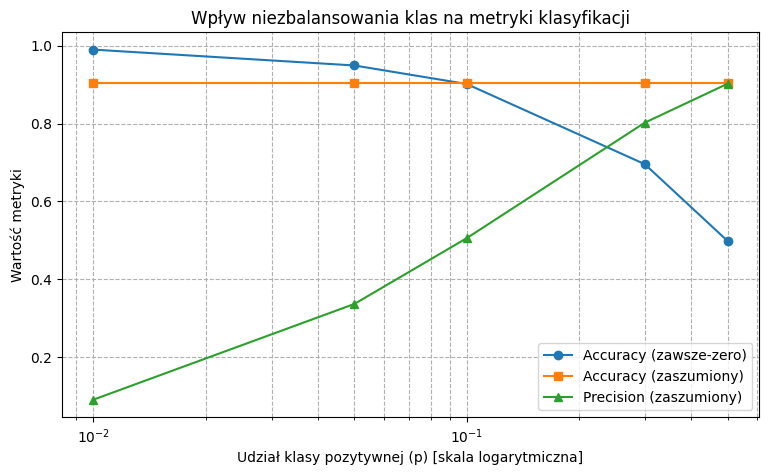

In [69]:
import matplotlib.pyplot as plt

# Twoje rozwiązanie (wykres)

plt.figure(figsize=(9, 5))

df_zero = df[df["model"] == "zawsze-zero"]
df_noisy = df[df["model"] == "zaszumiony"]

plt.plot(df_zero["p"], df_zero["accuracy"], label="Accuracy (zawsze-zero)", marker="o")
plt.plot(df_noisy["p"], df_noisy["accuracy"], label="Accuracy (zaszumiony)", marker="s")
plt.plot(df_noisy["p"], df_noisy["precision"], label="Precision (zaszumiony)", marker="^")

plt.xscale("log")
plt.xlabel("Udział klasy pozytywnej (p) [skala logarytmiczna]")
plt.ylabel("Wartość metryki")
plt.title("Wpływ niezbalansowania klas na metryki klasyfikacji")
plt.legend()
plt.grid(True, which="both", ls="--")

plt.show()

In [70]:
# TEST
assert set(df.columns) >= {"p", "model", "accuracy", "precision", "recall", "f1"}
assert len(df) == 10
z = df[(df["model"] == "zawsze-zero") & (df["p"] == 0.01)].iloc[0]
assert z["accuracy"] > 0.98 and z["recall"] == 0.0
print("D2 OK")

D2 OK


### Zadanie D3. Wnioski
Odpowiedz krótko (2–3 zdania na pytanie), odwołując się do liczb z tabeli:

1. Czy Twoje przewidywania z D1 się potwierdziły? Co Cię zaskoczyło?
2. Dla $p = 0.01$: który model ma wyższą accuracy, a który jest bardziej użyteczny? Dlaczego?
3. Model zaszumiony myli się zawsze w 10% przypadków. Dlaczego mimo to jego precision spada, gdy $p$ maleje?
4. Projektujesz system wykrywający rzadką chorobę. Którą metrykę zaraportujesz jako główną? Jakie konsekwencje dla pacjentów mają błędy FP, a jakie FN?

*Twoja odpowiedź:*

1. Tak, przewidywania z D1 w pełni się potwierdziły. Najbardziej uderzający jest tzw. paradoks dokładności - przy silnym niezbalansowaniu klas prymitywny model zawsze-zero osiąga wyższe accuracy niż model faktycznie analizujący dane, mimo że jest zupełnie bezużyteczny.

2. Dla p = 0.01 model zawsze-zero osiąga accuracy równe aż 0.99, podczas gdy model zaszumiony ma około 0.89. Mimo to bardziej użyteczny jest model zaszumiony - ma wysoki Recall (~0.90) i rzeczywiście wykrywa przypadki pozytywne, podczas gdy model zawsze-zero ma Recall = 0.0, więc ignoruje wszystkie anomalie.

3. Wynika to ze wzoru $\text{Precision} = \frac{TP}{TP + FP}$. Gdy p = 0.01, w zbiorze 10 000 próbek mamy tylko ~100 obiektów pozytywnych i aż ~9900 negatywnych. Nawet jeśli model myli się tylko w 10% przypadków, to z klasy negatywnej generuje aż ~990 fałszywych alarmów (FP), przy zaledwie ~90 poprawnych trafieniach (TP). W mianowniku liczba FP całkowicie dominuje nad TP.

4. Główną metryką powinien być Recall (oraz pomocniczo F1-score lub krzywa PR-AUC). W diagnostyce medycznej błąd FP oznacza skierowanie zdrowego pacjenta na niepotrzebne, stresujące badania kontrolne, natomiast błąd FN jest krytyczny, ponieważ chory pacjent zostaje odesłany do domu bez diagnozy i leczenia, co bezpośrednio zagraża jego życiu.  

---
## Część E. Zadania dodatkowe (dla chętnych / do domu)

**E1. Pliki.** Zapisz listę wyników (po jednym w linii) do pliku `scores.txt`. Wczytaj plik, oblicz średnią i zapisz do `report.txt` raport w formacie `Wczytano N wyników, średnia: X` (X z dokładnością do 3 miejsc po przecinku).

**E2. Dane od użytkownika.** Pobierz funkcją `input()` wynik modelu `s` i wypisz:
- `Podano niepoprawną wartość!`, gdy tekstu nie da się zamienić na liczbę (`try`/`except`),
- `Wynik poza zakresem 0–1`, gdy `s < 0` lub `s > 1`,
- `Model wymaga poprawy`, gdy `s < 0.7`,
- `Wynik akceptowalny`, gdy `0.7 ≤ s < 0.85`,
- `Wynik doskonały` w pozostałych przypadkach.

**E3. Duplikaty.** Usuń duplikaty z listy `["SVM", "SVM", "NeuralNet", "NeuralNet", "Transformer"]` **z zachowaniem kolejności** pierwszych wystąpień. Dlaczego samo `list(set(...))` tego nie gwarantuje?

**E4. Uogólnienie.** Rozszerz `make_data` o parametr pozwalający ustawić osobno odsetek błędów dla przykładów pozytywnych i negatywnych. Jak zmienia się wykres z D2, gdy model myli się w 10% pozytywnych, ale tylko w 1% negatywnych?

In [71]:
#E1. Pliki
scores = [0.83, 0.92, 0.78, 0.88, 0.95]

with open("scores.txt", "w") as f:
    for s in scores:
        f.write(f"{s}\n")

with open("scores.txt", "r") as f:
    read_scores = [float(line.strip()) for line in f if line.strip()]

mean_val = sum(read_scores) / len(read_scores)

with open("report.txt", "w") as f:
    f.write(f"Wczytano {len(read_scores)} wyników, średnia: {mean_val:.3f}")


#E2. Dane od użytkownika
user_input = input("Podaj wynik modelu: ")

try:
    s = float(user_input)
    if s < 0 or s > 1:
        print("Wynik poza zakresem 0–1")
    elif s < 0.7:
        print("Model wymaga poprawy")
    elif 0.7 <= s < 0.85:
        print("Wynik akceptowalny")
    else:
        print("Wynik doskonały")
except ValueError:
    print("Podano niepoprawną wartość!")


#E3. Duplikaty
data = ["SVM", "SVM", "NeuralNet", "NeuralNet", "Transformer"]

unique_data = []
for item in data:
    if item not in unique_data:
        unique_data.append(item)

# Odpowiedź - Samo list(set(...)) tego nie gwarantuje, ponieważ struktura set w Pythonie
# opiera się na tablicy mieszającej (hash table) i jest z definicji nieuporządkowana.
# Rzutowanie na set niszczy pierwotną kolejność elementów.


#E4. Uogólnienie
import numpy as np

def make_data_custom(p, n=10_000, error_pos=0.10, error_neg=0.01, seed=42):
    rng = np.random.default_rng(seed)
    y_true = (rng.random(n) < p).astype(int)
    flip_prob = np.where(y_true == 1, error_pos, error_neg)
    flip = rng.random(n) < flip_prob
    y_noisy = np.where(flip, 1 - y_true, y_true)
    return y_true, y_noisy

# Wpływ na wykres z D2
# Gdy błąd na przykładach negatywnych spada z 10% do 1%, liczba błędów FP drastcznie maleje.
# W rezultacie dla małych p (p = 0.05) metryka Precision nie załamuje się tak silnie
# i zamiast wynoszenia ~0.34 osiąga aż około 0.82. Krzywa Precision leży znacznie wyżej na wykresie.

Podaj wynik modelu: 0.5
Model wymaga poprawy
